# 02 · Preprocessing & Intent-Aware Feature Engineering — Doomscroll

**Goal:** make the data *model-ready* without leakage.

| | |
|---|---|
| **Reads** | `data/interim/*` from notebook 01 |
| **Writes** (`data/processed/`) | `events_enriched.parquet`, `features_{train,val,test}.parquet`, `user_interest.parquet`, `feature_dictionary.csv`, `id_maps_*.parquet`, `preprocess_config.json` |

**Plan**
1. Config (intent weights, windows, split) — *one place for the team to agree on*
2. k-core filtering (drop ultra-sparse users/items)
3. Attach categories, define **intent tier + score** per event
4. Time axis + **temporal** split with as-of feature windows (no leakage)
5. Build features: user · user×category · item · user×item
6. Integrity checks, feature dictionary, save

**Key design choices**
* An event is one logged exposure/interaction. The label is its **intent tier** (0 = seen only … 4 = share/follow), not just click/no-click. This is the "different levels of interest" idea.
* Features for a split are computed **only from events before that split's label window** (rolling as-of). Val/test never see the future.
* A fixed `LOOKBACK_DAYS` keeps feature scales comparable across splits.

In [1]:
import json, re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 80); pd.set_option("display.width", 170)
sns.set_theme(style="whitegrid", context="notebook")

ROOT = Path.cwd().parent if Path.cwd().name == "eda" else Path.cwd()
INTERIM, PROC, FIG = ROOT / "data" / "interim", ROOT / "data" / "processed", ROOT / "eda" / "figures"
for p in (PROC, FIG): p.mkdir(parents=True, exist_ok=True)
def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()

# ------------------------- TEAM CONFIG (edit here, re-run) -------------------------
INTENT_TIER   = {"click": 1, "long_view": 2, "like": 3, "comment": 3, "forward": 4, "follow": 4}
INTENT_WEIGHT = {"click": 1.0, "long_view": 2.0, "like": 3.0, "comment": 3.0, "forward": 4.0, "follow": 5.0}
NEG_FLAGS, NEG_WEIGHT = ["hate"], -3.0
SEARCH_CLICK_MIN_TIER, SEARCH_BONUS = 2, 2.0      # a click that comes from a search = explicit intent
HALF_LIFE_DAYS = 3.0                              # recency decay for interest scores
LOOKBACK_DAYS  = 7.0                              # history window used for features
SPLIT_FRACS    = (0.50, 0.70, 0.85)               # c1,c2,c3 as fractions of the time span
MIN_USER_EVENTS, MIN_ITEM_EVENTS = 5, 3           # k-core thresholds
SAMPLE_USERS   = None                             # e.g. 20000 for fast dev runs
LOCAL_OFFSET_HOURS = 8                            # Kuaishou = China time. Set 0 if timestamps are already local.
SEED = 42
# ------------------------------------------------------------------------------------
schema = json.load(open(INTERIM / "schema.json"))
flags = schema["flags_present"]
print("flags available:", flags)

flags available: ['click', 'like', 'follow', 'forward']


## 1 · Load (+ optional user sampling for dev)

In [2]:
ev = pd.read_parquet(INTERIM / "events.parquet")
items = pd.read_parquet(INTERIM / "items.parquet") if (INTERIM / "items.parquet").exists() else None
if SAMPLE_USERS:
    rng = np.random.default_rng(SEED)
    users = ev["user"].unique()
    keep = rng.choice(users, size=min(SAMPLE_USERS, len(users)), replace=False)
    ev = ev[ev["user"].isin(keep)].reset_index(drop=True)
print(f"{len(ev):,} events | {ev['user'].nunique():,} users | {ev['item'].nunique():,} items")

19,616,628 events | 25,877 users | 6,890,707 items


## 2 · k-core filtering
Users/items with almost no history cannot be modelled and add noise. We iterate because removing items can push users below the threshold. The retention table goes in the report.

In [3]:
def kcore(df, min_u, min_i, max_iter=5):
    for _ in range(max_iter):
        n = len(df)
        df = df[df["user"].map(df["user"].value_counts()) >= min_u]
        df = df[df["item"].map(df["item"].value_counts()) >= min_i]
        if len(df) == n: break
    return df

before = dict(events=len(ev), users=ev["user"].nunique(), items=ev["item"].nunique())
ev = kcore(ev, MIN_USER_EVENTS, MIN_ITEM_EVENTS).reset_index(drop=True)
after = dict(events=len(ev), users=ev["user"].nunique(), items=ev["item"].nunique())
ret = pd.DataFrame({"before": before, "after": after}); ret["kept_%"] = (ret["after"] / ret["before"] * 100).round(1)
ret

,before,after,kept_%
events,19616628,13067469,66.6
users,25877,25865,100.0
items,6890707,1304223,18.9


## 3 · Categories, intent tier & intent score

,events,mean_score,share_pct
tier,,,
0,6771934,0.000000,51.82
1,5650752,1.000000,43.24
2,261577,3.000000,2.00
3,305462,3.754362,2.34
4,77744,6.424715,0.59


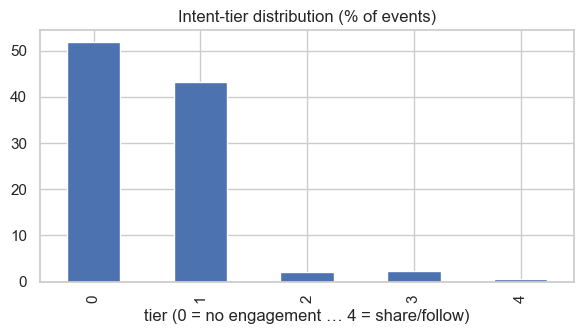

In [4]:
if items is not None:
    ev["cat"] = ev["item"].map(items.set_index("item")["cat"]).fillna("unknown")
else:
    ev["cat"] = "unknown"
cat_list = sorted(ev["cat"].unique())
cat_codes = {c: i for i, c in enumerate(cat_list)}
ev["cat"] = pd.Categorical(ev["cat"], categories=cat_list)

tier = np.zeros(len(ev), dtype="int8"); score = np.zeros(len(ev), dtype="float32")
for f, t in INTENT_TIER.items():
    if f in ev: tier = np.maximum(tier, ev[f].to_numpy() * np.int8(t))
for f, w in INTENT_WEIGHT.items():
    if f in ev: score += ev[f].to_numpy() * np.float32(w)
is_search = (ev["source"] == "search").to_numpy()
if "click" in ev:
    sc = is_search & (ev["click"].to_numpy() == 1)
    tier = np.where(sc, np.maximum(tier, SEARCH_CLICK_MIN_TIER), tier).astype("int8")
    score = score + sc * np.float32(SEARCH_BONUS)
neg = np.zeros(len(ev), dtype="int8")
for f in NEG_FLAGS:
    if f in ev:
        neg |= ev[f].to_numpy().astype("int8"); score = score + ev[f].to_numpy() * np.float32(NEG_WEIGHT)

ev["tier"], ev["score"], ev["neg"] = tier, score.astype("float32"), neg
ev["pos"] = (tier > 0).astype("int8"); ev["is_search"] = is_search.astype("int8")

t = ev.groupby("tier").agg(events=("user", "size"), mean_score=("score", "mean")).assign(share_pct=lambda d: (d["events"] / d["events"].sum() * 100).round(2))
display(t)
ax = t["share_pct"].plot(kind="bar", figsize=(6, 3.5), title="Intent-tier distribution (% of events)")
ax.set_xlabel("tier (0 = no engagement … 4 = share/follow)"); savefig("02_tier_distribution")

## 4 · Time axis and temporal split
Three rolling windows (`asof` = end of history, label window follows it):

| split | history (features) | label window |
|---|---|---|
| train | `[c1 - lookback, c1)` | `[c1, c2)` |
| val   | `[c2 - lookback, c2)` | `[c2, c3)` |
| test  | `[c3 - lookback, c3)` | `[c3, end]` |

In [5]:
T0 = ev["ts"].min().normalize()
ev["t"] = ((ev["ts"] - T0) / pd.Timedelta(days=1)).astype("float32")
ev["day"] = np.floor(ev["t"]).astype("int16")
loc = ev["ts"] + pd.Timedelta(hours=LOCAL_OFFSET_HOURS)
ev["hour"], ev["dow"] = loc.dt.hour.astype("int8"), loc.dt.dayofweek.astype("int8")

span = float(ev["t"].max()) + 1e-6
c1, c2, c3 = [span * f for f in SPLIT_FRACS]
SPLITS = {"train": (c1, c1, c2), "val": (c2, c2, c3), "test": (c3, c3, span + 1)}   # (asof, label_start, label_end)
split_tbl = pd.DataFrame({k: dict(history_from=T0 + pd.Timedelta(days=max(0, a - LOOKBACK_DAYS)), asof=T0 + pd.Timedelta(days=a),
                                  label_to=T0 + pd.Timedelta(days=min(b, span)), label_days=round(min(b, span) - s, 2))
                          for k, (a, s, b) in SPLITS.items()}).T
display(split_tbl)
if c1 < LOOKBACK_DAYS: print(f"WARNING: train history ({c1:.1f} d) is shorter than LOOKBACK_DAYS={LOOKBACK_DAYS}; train features will be 'younger' than val/test.")

,history_from,asof,label_to,label_days
train,2023-05-24 16:25:11.075304492,2023-05-31 16:25:11.075304492,2023-06-04 13:23:15.505426289,3.87
val,2023-05-28 13:23:15.505426289,2023-06-04 13:23:15.505426289,2023-06-07 11:06:48.828017636,2.91
test,2023-05-31 11:06:48.828017636,2023-06-07 11:06:48.828017636,2023-06-10 08:50:22.150608984,2.91


## 5 · Feature builder
Everything is computed from the history window **only**. Feature groups:

* **user (`u_`)** – activity level, behaviour mix (like-rate, share-rate …), search share, recency
* **user×category (`uc_`)** – the *interest representation*: counts, intent-weighted scores, time-decayed scores, share of the user's interest in this category, lift vs exposure, recency, repeat interactions
* **item (`i_`)** – popularity, engagement rate, mean intent, duration
* **user×item (`ui_`)** – previous interactions with the same video (repeat behaviour)
* **context (`ctx_`)** – hour/weekday cyclical encoding, search vs feed

In [6]:
def history_tables(ev, asof):
    h = ev[(ev["t"] >= asof - LOOKBACK_DAYS) & (ev["t"] < asof)].copy()
    assert len(h) == 0 or h["t"].max() < asof, "LEAKAGE: history reaches into the label window"
    h["score_pos"] = h["score"].clip(lower=0)
    h["w"] = h["score_pos"] * 0.5 ** ((asof - h["t"]) / HALF_LIFE_DAYS)
    h["recent24"] = ((asof - h["t"]) <= 1.0).astype("int8")

    # ---- user level
    g = h.groupby("user", observed=True)
    uf = g.agg(u_n_events=("item", "size"), u_n_items=("item", "nunique"), u_active_days=("day", "nunique"),
               u_mean_score=("score", "mean"), u_pos_rate=("pos", "mean"), u_search_share=("is_search", "mean"),
               u_last_t=("t", "max"), u_recent24=("recent24", "sum"), u_n_cats=("cat", "nunique"))
    uf = uf.join(g[[f for f in flags]].mean().add_prefix("u_rate_"))
    if "play_ratio" in h: uf = uf.join(g["play_ratio"].mean().rename("u_play_ratio"))
    uf["u_recency"] = asof - uf["u_last_t"]; uf = uf.drop(columns="u_last_t").reset_index()

    # ---- user x category (interest representation)
    hc = h.groupby(["user", "cat"], observed=True).agg(uc_n=("item", "size"), uc_items=("item", "nunique"), uc_pos=("pos", "sum"),
                                                      uc_score=("score_pos", "sum"), uc_decay=("w", "sum"), uc_last_t=("t", "max")).reset_index()
    tot = hc.groupby("user", observed=True)[["uc_n", "uc_decay"]].transform("sum")
    hc["uc_exposure_share"] = hc["uc_n"] / tot["uc_n"]
    hc["uc_decay_share"] = hc["uc_decay"] / tot["uc_decay"].where(tot["uc_decay"] > 0)
    hc["uc_decay_share"] = hc["uc_decay_share"].fillna(0)
    hc["uc_lift"] = hc["uc_decay_share"] / hc["uc_exposure_share"]
    hc["uc_repeat"] = hc["uc_n"] - hc["uc_items"]
    hc["uc_recency"] = asof - hc["uc_last_t"]; hc = hc.drop(columns="uc_last_t")

    # ---- item level
    agg = dict(i_n=("user", "size"), i_users=("user", "nunique"), i_mean_score=("score", "mean"), i_pos_rate=("pos", "mean"))
    if "duration" in h: agg["i_duration"] = ("duration", "median")
    if "play_ratio" in h: agg["i_play_ratio"] = ("play_ratio", "mean")
    itf = h.groupby("item").agg(**agg).reset_index()

    # ---- user x item
    ui = h.groupby(["user", "item"]).agg(ui_prior_n=("t", "size"), ui_prior_max_tier=("tier", "max"), ui_prior_score=("score_pos", "sum")).reset_index()
    return uf, hc, itf, ui

def build_split(ev, asof, a, b):
    uf, hc, itf, ui = history_tables(ev, asof)
    L = ev[(ev["t"] >= a) & (ev["t"] < b)][["user", "item", "cat", "source", "t", "hour", "dow", "is_search", "tier", "pos", "neg"]]
    L = L.rename(columns={"tier": "label_tier", "pos": "label_pos", "neg": "label_neg", "hour": "ctx_hour", "dow": "ctx_dow", "is_search": "ctx_is_search"})
    L["label_strong"] = (L["label_tier"] >= 3).astype("int8")
    X = (L.merge(uf, on="user", how="left").merge(hc, on=["user", "cat"], how="left")
          .merge(itf, on="item", how="left").merge(ui, on=["user", "item"], how="left"))
    X["cold_user"] = X["u_n_events"].isna().astype("int8")
    X["cold_item"] = X["i_n"].isna().astype("int8")
    X["cold_uc"] = X["uc_n"].isna().astype("int8")
    if "i_duration" in X: X["i_duration"] = X["i_duration"].fillna(X["i_duration"].median())
    rec_cols = [c for c in X.columns if c.endswith("recency")]
    X[rec_cols] = X[rec_cols].fillna(LOOKBACK_DAYS)
    feat = [c for c in X.columns if re.match(r"^(u|uc|i|ui)_", c)]
    X[feat] = X[feat].fillna(0).astype("float32")
    X["ctx_hour_sin"] = np.sin(2 * np.pi * X["ctx_hour"] / 24).astype("float32")
    X["ctx_hour_cos"] = np.cos(2 * np.pi * X["ctx_hour"] / 24).astype("float32")
    X["ctx_is_weekend"] = (X["ctx_dow"] >= 5).astype("int8")
    X["cat_id"] = X["cat"].astype(str).map(cat_codes).astype("int16")
    X = X.drop(columns=[c for c in ("source",) if c in X] )   # ctx_is_search carries it
    return X, hc.assign(asof=asof)

## 6 · Build train / val / test and save

In [7]:
ev.to_parquet(PROC / "events_enriched.parquet", index=False)

interest, summary = [], []
for name, (asof, a, b) in SPLITS.items():
    X, hc = build_split(ev, asof, a, b)
    assert X["t"].min() >= a - 1e-6, "label rows start before label window"
    X.to_parquet(PROC / f"features_{name}.parquet", index=False)
    interest.append(hc[["user", "cat", "uc_n", "uc_decay_share", "uc_exposure_share", "uc_lift"]].assign(split=name))
    summary.append(dict(split=name, rows=len(X), users=X["user"].nunique(), items=X["item"].nunique(),
                        pos_rate_pct=X["label_pos"].mean() * 100, strong_rate_pct=X["label_strong"].mean() * 100, search_share_pct=X["ctx_is_search"].mean() * 100,
                        cold_user_pct=X["cold_user"].mean() * 100, cold_item_pct=X["cold_item"].mean() * 100, cold_user_cat_pct=X["cold_uc"].mean() * 100))
    print(f"{name:5s} -> {X.shape}")
pd.concat(interest).assign(cat=lambda d: d["cat"].astype(str)).to_parquet(PROC / "user_interest.parquet", index=False)
summ = pd.DataFrame(summary).set_index("split").round(3)
summ

train -> (2730505, 51)
val   -> (1508044, 51)
test  -> (1337426, 51)


,rows,users,items,pos_rate_pct,strong_rate_pct,search_share_pct,cold_user_pct,cold_item_pct,cold_user_cat_pct
split,,,,,,,,,
train,2730505,12506,585561,50.762,3.064,12.270,0.144,47.439,4.889
val,1508044,9995,415145,48.170,2.818,11.237,0.624,46.295,4.109
test,1337426,9836,345650,51.380,3.047,8.006,3.301,44.794,13.201


## 7 · Integrity checks

In [8]:
Xtr = pd.read_parquet(PROC / "features_train.parquet")
label_cols = [c for c in Xtr.columns if c.startswith("label_")]
id_cols = ["user", "item", "cat", "t"]
feat_cols = [c for c in Xtr.columns if c not in label_cols + id_cols]

checks = {
    "no NaN in features": int(Xtr[feat_cols].isna().sum().sum()) == 0,
    "label columns never used as features": not any(c.startswith("label_") for c in feat_cols),
    "train labels strictly after train history": Xtr["t"].min() >= c1 - 1e-6,
    "val after train / test after val": (pd.read_parquet(PROC / "features_val.parquet", columns=["t"])["t"].min() >= c2 - 1e-6) and
                                        (pd.read_parquet(PROC / "features_test.parquet", columns=["t"])["t"].min() >= c3 - 1e-6),
    "positive class present in every split": bool((summ["pos_rate_pct"] > 0).all()),
}
display(pd.Series(checks, name="passed").to_frame())
assert all(checks.values()), "An integrity check failed - fix before modelling"
print(f"{len(feat_cols)} model features:", feat_cols)

,passed
no NaN in features,True
label columns never used as features,True
train labels strictly after train history,True
val after train / test after val,True
positive class present in every split,True


43 model features: ['ctx_hour', 'ctx_dow', 'ctx_is_search', 'u_n_events', 'u_n_items', 'u_active_days', 'u_mean_score', 'u_pos_rate', 'u_search_share', 'u_recent24', 'u_n_cats', 'u_rate_click', 'u_rate_like', 'u_rate_follow', 'u_rate_forward', 'u_play_ratio', 'u_recency', 'uc_n', 'uc_items', 'uc_pos', 'uc_score', 'uc_decay', 'uc_exposure_share', 'uc_decay_share', 'uc_lift', 'uc_repeat', 'uc_recency', 'i_n', 'i_users', 'i_mean_score', 'i_pos_rate', 'i_duration', 'i_play_ratio', 'ui_prior_n', 'ui_prior_max_tier', 'ui_prior_score', 'cold_user', 'cold_item', 'cold_uc', 'ctx_hour_sin', 'ctx_hour_cos', 'ctx_is_weekend', 'cat_id']


## 8 · Feature dictionary + quick distributions

,feature,group,description
0,ctx_hour,ctx,local hour
1,ctx_dow,ctx,weekday (0=Mon)
2,ctx_is_search,ctx,1 = this event came from search
3,u_n_events,u,events in history window
4,u_n_items,u,distinct videos seen
5,u_active_days,u,distinct active days
6,u_mean_score,u,mean intent score per event
7,u_pos_rate,u,share of events with any engagement
8,u_search_share,u,share of events that came from search
9,u_recent24,u,events in last 24h before cutoff


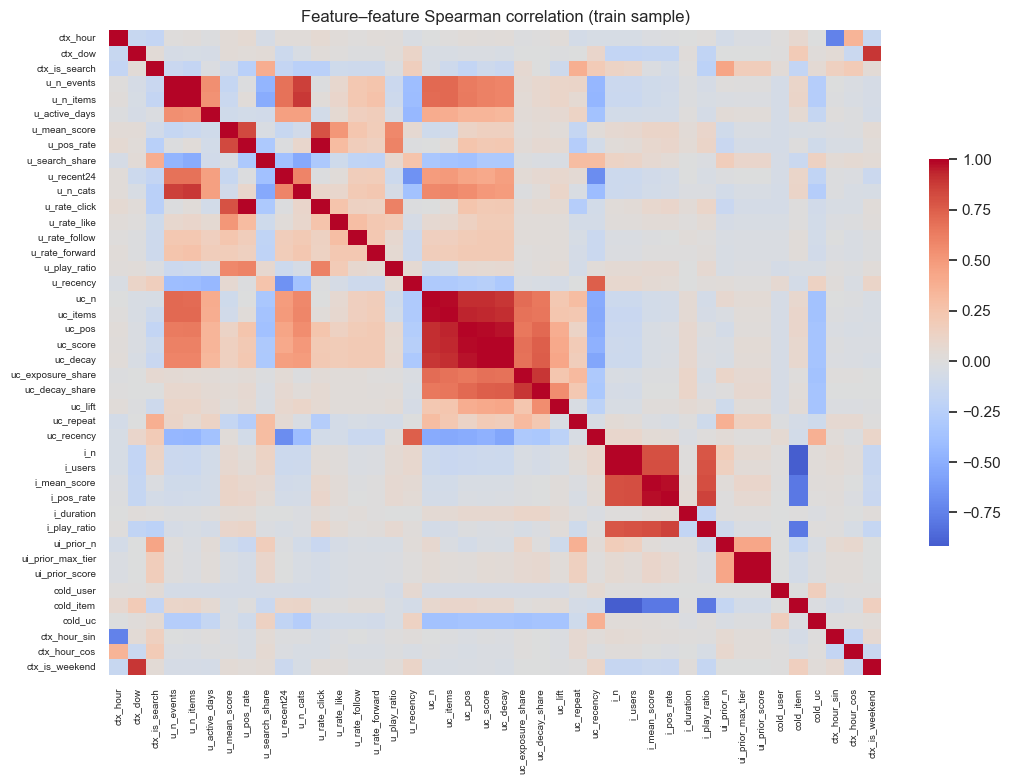

In [9]:
DESC = {
 "u_n_events": "events in history window", "u_n_items": "distinct videos seen", "u_active_days": "distinct active days", "u_mean_score": "mean intent score per event",
 "u_pos_rate": "share of events with any engagement", "u_search_share": "share of events that came from search", "u_recent24": "events in last 24h before cutoff",
 "u_n_cats": "distinct categories seen", "u_recency": "days since last event", "u_play_ratio": "mean watch ratio",
 "uc_n": "user's events in this category", "uc_items": "distinct videos in this category", "uc_pos": "engaged events in this category", "uc_score": "sum of intent scores in category",
 "uc_decay": "time-decayed intent score in category", "uc_exposure_share": "share of user's exposure going to this category", "uc_decay_share": "share of user's decayed intent in this category",
 "uc_lift": "intent share / exposure share (>1 = user over-engages with category)", "uc_repeat": "repeat interactions inside category", "uc_recency": "days since last event in this category",
 "i_n": "item exposures in history", "i_users": "distinct users who saw item", "i_mean_score": "item mean intent score", "i_pos_rate": "item engagement rate", "i_duration": "video duration (median)", "i_play_ratio": "item mean watch ratio",
 "ui_prior_n": "times this user already saw this video", "ui_prior_max_tier": "highest prior tier on this video", "ui_prior_score": "summed prior intent on this video",
 "cold_user": "1 = user unseen in history", "cold_item": "1 = item unseen in history", "cold_uc": "1 = user never saw this category in history",
 "ctx_hour": "local hour", "ctx_dow": "weekday (0=Mon)", "ctx_is_search": "1 = this event came from search", "ctx_hour_sin": "cyclic hour", "ctx_hour_cos": "cyclic hour", "ctx_is_weekend": "weekend flag", "cat_id": "integer category code",
}
fd = pd.DataFrame({"feature": feat_cols})
fd["group"] = fd["feature"].str.extract(r"^(u_rate|uc|ui|u|i|ctx|cold|cat)")[0].replace({"u_rate": "u"})
fd["description"] = fd["feature"].map(lambda f: DESC.get(f, "behaviour rate of this action in history" if f.startswith("u_rate_") else ""))
fd.to_csv(PROC / "feature_dictionary.csv", index=False)
display(fd)

num = Xtr[[c for c in feat_cols if c not in ("cat_id",)]].sample(min(len(Xtr), 200_000), random_state=SEED)
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(num.corr(method="spearman"), cmap="coolwarm", center=0, ax=ax, cbar_kws={"shrink": .6}, xticklabels=True, yticklabels=True)
ax.set_title("Feature–feature Spearman correlation (train sample)"); ax.tick_params(labelsize=7)
savefig("02_feature_correlation")

## 9 · ID maps and config for the model notebooks

In [10]:
users_idx = pd.DataFrame({"user": np.sort(ev["user"].unique())}); users_idx["user_idx"] = np.arange(len(users_idx))
items_idx = pd.DataFrame({"item": np.sort(ev["item"].unique())}); items_idx["item_idx"] = np.arange(len(items_idx))
users_idx.to_parquet(PROC / "id_maps_users.parquet", index=False); items_idx.to_parquet(PROC / "id_maps_items.parquet", index=False)

cfg = dict(INTENT_TIER=INTENT_TIER, INTENT_WEIGHT=INTENT_WEIGHT, NEG_FLAGS=NEG_FLAGS, NEG_WEIGHT=NEG_WEIGHT, SEARCH_CLICK_MIN_TIER=SEARCH_CLICK_MIN_TIER,
           SEARCH_BONUS=SEARCH_BONUS, HALF_LIFE_DAYS=HALF_LIFE_DAYS, LOOKBACK_DAYS=LOOKBACK_DAYS, SPLIT_FRACS=SPLIT_FRACS, MIN_USER_EVENTS=MIN_USER_EVENTS,
           MIN_ITEM_EVENTS=MIN_ITEM_EVENTS, SAMPLE_USERS=SAMPLE_USERS, LOCAL_OFFSET_HOURS=LOCAL_OFFSET_HOURS, T0=str(T0), cat_codes=cat_codes,
           flags=flags, splits={k: dict(asof=v[0], label_start=v[1], label_end=v[2]) for k, v in SPLITS.items()}, feature_cols=feat_cols)
json.dump(cfg, open(PROC / "preprocess_config.json", "w"), indent=2, default=str)
print(sorted(p.name for p in PROC.iterdir()))

['events_enriched.parquet', 'feature_dictionary.csv', 'features_test.parquet', 'features_train.parquet', 'features_val.parquet', 'id_maps_items.parquet', 'id_maps_users.parquet', 'preprocess_config.json', 'user_interest.parquet']


## Hand-off
* **Model input:** `features_{train,val,test}.parquet` (`feature_cols` in `preprocess_config.json`), labels `label_tier` (0–4, for ordinal/graded relevance), `label_pos`, `label_strong`.
* **Intent-aware vs equal-weight baseline:** the equal-weight baseline should use `label_pos`; the intent-aware model uses `label_tier` or `INTENT_WEIGHT`.
* **Evaluation protocol:** rank the impressions each user had in the label window (logged-exposure re-ranking). Compare NDCG@K with graded gains from `label_tier`.
* Scaling/encoding (e.g. standardise, embed `cat_id`) belongs in the model pipeline and must be **fit on train only**.